# 4. K-Nearest Neighbors (KNN) Regression

## Lý thuyết & Nguyên lý

KNN là mô hình **phi tham số** (non-parametric): không học một bộ tham số cố định như các hệ số $\beta$ trong hồi quy tuyến tính, mà "ghi nhớ" toàn bộ dữ liệu huấn luyện và suy luận ngay tại thời điểm dự đoán (*lazy learning*).

### 4.1. Cơ chế dự đoán

Với điểm mới $x^*$, KNN tìm $k$ điểm dữ liệu huấn luyện **gần nhất** theo một thước đo khoảng cách (mặc định là Euclidean):

$$d(x^*, x_i) = \sqrt{\sum_{j=1}^{p}\left(x^*_j - x_{ij}\right)^2} \quad (\text{Euclidean}) \qquad d_1(x^*, x_i) = \sum_{j=1}^{p}\left|x^*_j - x_{ij}\right| \quad (\text{Manhattan})$$

Trong hồi quy, giá trị dự đoán là **trung bình cộng** (hoặc trung bình có trọng số) của $y$ tại $k$ điểm láng giềng đó:

$$\hat{y}(x^*) = \frac{\sum_{i \in \mathcal{N}_k(x^*)} w_i \, y_i}{\sum_{i \in \mathcal{N}_k(x^*)} w_i}$$

- `weights='uniform'`: $w_i = 1$ → bình quân đồng giản.
- `weights='distance'`: $w_i = \dfrac{1}{d(x^*, x_i)}$ → điểm **gần hơn có ảnh hưởng lớn hơn** (khi $x^*$ trùng một điểm huấn luyện, trọng số của điểm đó là vô hạn → dự đoán chính bằng nhãn của nó).

### 4.2. Vai trò của siêu tham số $k$

- **$k$ quá nhỏ** (ví dụ $k=1$): ranh giới dự đoán rất "gợn sóng", nhạy tuyệt đối với nhiễu → **overfitting**, phương sai cao.
- **$k$ quá lớn**: dự đoán tiến về trung bình toàn cục của dữ liệu → **underfitting**, bias cao.
- Trong phân loại, chọn $k$ **lẻ** để tránh trường hợp hòa phiếu.

### 4.3. Hai lưu ý then chốt

1. **Bắt buộc chuẩn hóa đặc trưng** (`StandardScaler`): KNN đo khoảng cách theo đơn vị của từng đặc trưng; đặc trưng có thang số lớn (ví dụ thu nhập: hàng triệu) sẽ lấn át hoàn toàn đặc trưng có thang số nhỏ (ví dụ tuổi: hàng chục).
2. **Curse of dimensionality** (lời nguyền chiều cao): khi số chiều $p$ lớn, khoảng cách tới điểm gần nhất và điểm xa nhất hội tụ về nhau → khái niệm "láng giềng gần" trở nên vô nghĩa, hiệu năng suy giảm. KNN thường chỉ tốt khi $p$ nhỏ hoặc sau khi giảm chiều (PCA).


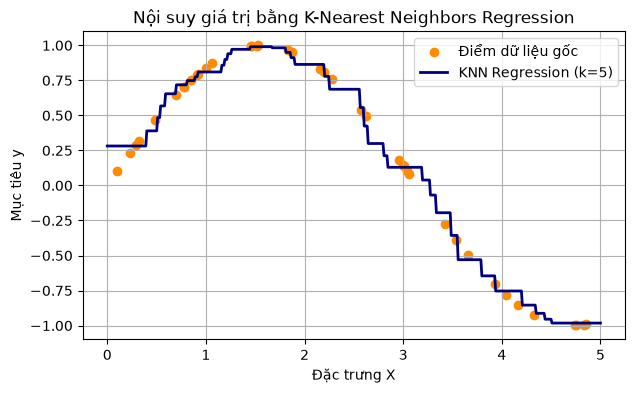

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import KNeighborsRegressor

# 1. Dữ liệu: hàm sin sạch (chưa có nhiễu)
np.random.seed(42)
X = np.sort(5 * np.random.rand(40, 1), axis=0)
y = np.sin(X).ravel()

# 2. Huấn luyện KNN Regression với k = 5
knn = KNeighborsRegressor(n_neighbors=5).fit(X, y)

# 3. Đường dự đoán trên lưới điểm test mịn
X_test = np.linspace(0, 5, 500)[:, np.newaxis]

plt.figure(figsize=(7, 4))
plt.scatter(X, y, color='darkorange', label='Điểm dữ liệu gốc')
plt.plot(
    X_test,
    knn.predict(X_test),
    color='navy',
    label='KNN Regression (k=5)',
    linewidth=2,
)
plt.title('Nội suy giá trị bằng K-Nearest Neighbors Regression')
plt.xlabel('Đặc trưng X')
plt.ylabel('Mục tiêu y')
plt.legend()
plt.grid(True)
plt.show()


## Ý nghĩa của biểu đồ

Đường dự đoán navy là chuỗi các **đoạn ngang** (bậc thang nhỏ): giữa hai điểm dữ liệu kế nhau, tập hợp 5 láng giềng gần nhất không đổi → giá trị trung bình của chúng không đổi. Vì vậy KNN regression về bản chất là một **hàm nội suy phi parametric** — càng dữ liệu dày (nhiều mẫu) thì bậc thang càng nhỏ và trông như đường cong mượt.

---

## Tổng quan mô hình

### Ưu điểm

- **Rất đơn giản, không giả định gì** về hình dạng hàm số (phi tham số): bắt được cả hàm phi tuyến phức tạp nếu dữ liệu đủ dày.
- **Công thức dự đoán trực quan** — dễ giải thích cho người không chuyên ("dự đoán theo 5 điểm tương tự gần nhất").
- **Mượt dần khi tăng $k$** — dùng được cho cả bài toán cần độ nhạy cao ($k$ nhỏ) lẫn độ ổn định cao ($k$ lớn).
- **Hiệu năng tốt với dữ liệu nhỏ, ít chiều**, ranh giới phức tạp nhưng mật độ điểm đều.

### Nhược điểm

- **Chậm khi dự đoán:** không có bước huấn luyện, nhưng mỗi lần dự đoán phải tính khoảng cách tới **toàn bộ** $n$ điểm huấn luyện — độ phức tạp $O(n \cdot p)$ mỗi truy vấn (có thể giảm bằng KD-Tree/Ball Tree hoặc approximate NN).
- **Bắt buộc chuẩn hóa** dữ liệu, không thì đặc trưng thang lớn lấn át.
- **Yếu ở chiều cao** (curse of dimensionality) và với dữ liệu thưa, lệch mật độ.
- **Không extrapolate được:** giá trị dự đoán luôn nằm trong khoảng $[\min(y), \max(y)]$ của các láng giềng — không thể dự đoán ngoài miền dữ liệu.
- **Không cho ra được hàm số tường minh** để diễn giải.

### Siêu tham số quan trọng

| Tham số | Vai trò | Gợi ý |
| :--- | :--- | :--- |
| `n_neighbors` | Số láng giềng $k$ | Bắt đầu với $k \approx \sqrt{n}$; chọn qua GridSearchCV |
| `weights` | Uniform hay nghịch đảo khoảng cách | Dữ liệu lệch mật độ → dùng `distance` |
| `metric` | Euclidean, Manhattan, Minkowski... | Dữ liệu nhiều chiều/tham số: Minkowski |
| `p` | Tham số Minkowski ($p=1$ Manhattan, $p=2$ Euclidean) | Đa số bài toán: 2 |
| `algorithm` | `auto` / `ball_tree` / `kd_tree` / `brute` | Để `auto`; KD-Tree tốt cho $p$ nhỏ |

### Các trường hợp sử dụng thực tế

| Lĩnh vực | Ứng dụng cụ thể | Đặc trưng đầu vào ($X$) | Mục tiêu ($y$) |
| :--- | :--- | :--- | :--- |
| **Thương mại điện tử** | Dự đoán giá trị món hàng tương tự | Kích thước, trọng lượng, thương hiệu, năm sản xuất | Giá giao dịch gần nhất |
| **Tài chính** | Ước định giá tài sản theo so sánh | Diện tích, vị trí, tiện ích của các bất động sản tương đồng | Giá giao dịch |
| **Y tế** | Ước chỉ số lâm sàng từ hồ sơ tương tự | Chỉ số sinh trắc, tiền sử, kết quả xét nghiệm | Chỉ số tiên lượng |
| **Nông nghiệp** | Ước năng suất vùng lân cận | Đất, khí hậu, giống cây, lượng phân bón | Sản lượng (tấn/ha) |
| **Xử lý tín hiệu** | Nội suy chuỗi dữ liệu thời gian | Trượt cửa sổ thời gian quá khứ | Giá trị bước kế tiếp |

### Mẹo thực hành

- Luôn bọc `Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor())])` — nếu không, kết quả có thể sai trầm trọng.
- Dùng `GridSearchCV` quét `n_neighbors` lẻ từ 1 đến $\sqrt{n}$ để tìm $k$ tốt nhất.
- Với dữ liệu lớn, cân nhắc `algorithm='ball_tree'` hoặc thu hẹp không gian bằng PCA trước khi áp dụng KNN.


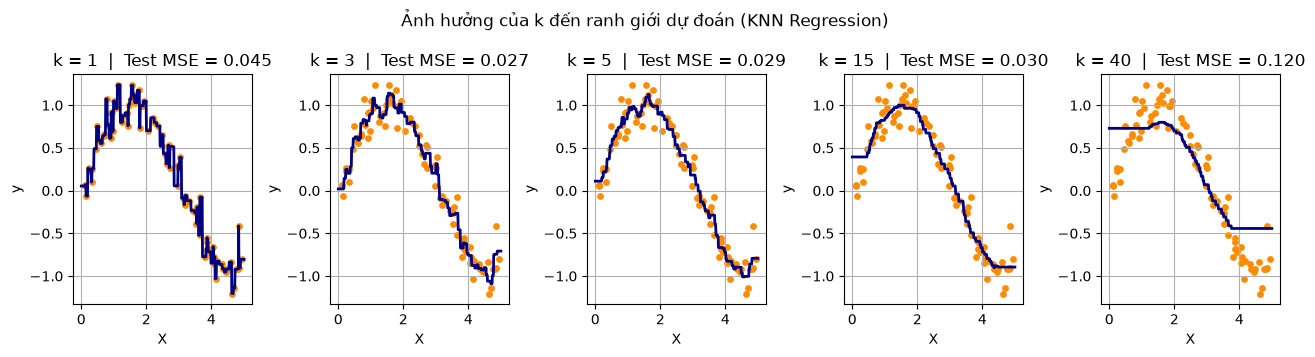

Tổng hợp Test MSE theo k:
  k= 1  ->  MSE = 0.0453
  k= 3  ->  MSE = 0.0266
  k= 5  ->  MSE = 0.0290
  k=15  ->  MSE = 0.0304
  k=40  ->  MSE = 0.1195


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

# 1. Dữ liệu: hàm sin + nhiễu, nhiều mẫu hơn
np.random.seed(42)
X = np.sort(5 * np.random.rand(120, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.15, X.shape[0])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. So sánh nhiều giá trị k khác nhau
ks = [1, 3, 5, 15, 40]
X_grid = np.linspace(0, 5, 500)[:, np.newaxis]

plt.figure(figsize=(13, 3.6))
for i, k in enumerate(ks, 1):
    knn = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    mse = mean_squared_error(y_test, knn.predict(X_test))

    plt.subplot(1, len(ks), i)
    plt.scatter(X_train, y_train, s=15, color='darkorange', label='Train')
    plt.plot(X_grid, knn.predict(X_grid), color='navy', linewidth=2, label='Dự đoán')
    plt.title(f'k = {k}  |  Test MSE = {mse:.3f}')
    plt.xlabel('X')
    plt.ylabel('y')
    plt.grid(True)

plt.suptitle('Ảnh hưởng của k đến ranh giới dự đoán (KNN Regression)')
plt.tight_layout()
plt.show()

print("Tổng hợp Test MSE theo k:")
for k in ks:
    knn = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    print(f"  k={k:>2d}  ->  MSE = {mean_squared_error(y_test, knn.predict(X_test)):.4f}")


## Giải thích kết quả

- **$k=1$:** đường dự đoán bám từng điểm, "gợn" mạnh → phương sai cao nhất, khớp cả nhiễu (overfitting).
- **$k=3, 5$:** ranh giới bớt gợn nhưng vẫn bám chi tiết hàm sin — vùng cân bằng tốt (bias–variance tradeoff).
- **$k=15, 40$:** đường dự đoán ngày càng phẳng, tới $k=40$ gần như trở thành đường ngang (trung bình toàn cục) → **underfitting**, mất hoàn toàn cấu trúc sin.

Thông điệp: **$k$ là núm điều khiển độ trơn của mô hình** — chọn qua cross-validation, không nên đoán mò.
